# Pipeline Demo
> Demonstrates the pipeline fitting/transforming data.

In [10]:
import zipfile
import numpy as np
from pathlib import Path
import nibabel as nib
import matplotlib.pyplot as plt

## Imaging Analysis & Demonstration

In [24]:
def get_image_data(scan_type: str) -> tuple[list[np.ndarray], list[tuple[int, int, int]]]:
    '''
        Gets the image data for all scans of a given scan orientation

        @param scan_type: The scan orientation. Must be one of "axial", "coronal", or "sagittal"

        @return: A tuple containing a list of foreground masks and a list of image shapes
    '''
    zip_path = Path(f"../data/scans/mri_{scan_type}.zip")

    foregrounds = []
    img_shape = []

    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            name = Path(member.filename).name
            if member.is_dir() or not name.endswith(".nii"):
                continue
            # loading the image
            img_nib = nib.Nifti1Image.from_bytes(zf.read(member))
            # put every scan in the same orientation so axes mean the same thing across sites
            img_nib = nib.as_closest_canonical(img_nib)
            # extract the img 
            img_nib = np.squeeze(img_nib.get_fdata(dtype=np.float32))
            foreground = img_nib > 0.2 * np.percentile(img_nib, 99)
            foregrounds.append(foreground)
            img_shape.append(img_nib.shape)
    
    return foregrounds, img_shape


In [26]:
ax_foregrounds, ax_img_shape = get_image_data("axial")
sag_foregrounds, sag_img_shape = get_image_data("sagittal")
cor_foregrounds, cor_img_shape = get_image_data("coronal")

### Check Foreground Pixel Distribution

We need to:
- Remove the images with ~empty foregrounds.
- Clip the bright outliers in the foreground. 
- Use the z-score to normalize the intensities of the images.
- Normalize the background to be the same across all scans.

**Why does sagittal have a peak at ~0.85 and coronal have a peak at ~0.0?**

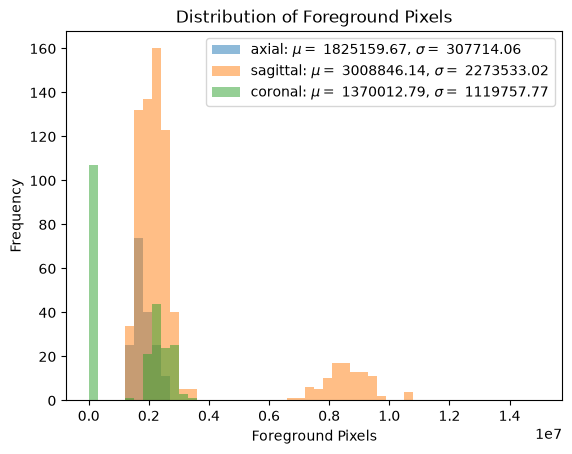

In [ ]:
plt.hist([np.sum(fg) for fg in ax_foregrounds], bins=50, range=(0,1.5e7), alpha=0.5, 
    label="axial: $\\mu=$ {:.2f}, $\\sigma=$ {:.2f}".format(
        np.mean([np.sum(fg) for fg in ax_foregrounds]), np.std([np.sum(fg) for fg in ax_foregrounds])
        ))

plt.hist([np.sum(fg) for fg in sag_foregrounds], bins=50, range=(0,1.5e7), alpha=0.5, 
    label="sagittal: $\\mu=$ {:.2f}, $\\sigma=$ {:.2f}".format(
        np.mean([np.sum(fg) for fg in sag_foregrounds]), np.std([np.sum(fg) for fg in sag_foregrounds])
        ))

plt.hist([np.sum(fg) for fg in cor_foregrounds], bins=50, range=(0,1.5e7), alpha=0.5, 
    label="coronal: $\\mu=$ {:.2f}, $\\sigma=$ {:.2f}".format(
        np.mean([np.sum(fg) for fg in cor_foregrounds]), np.std([np.sum(fg) for fg in cor_foregrounds])
        ))
        
plt.xlabel("Foreground Pixels")
plt.ylabel("Frequency")
plt.title("Distribution of Foreground Pixels")
plt.legend()
plt.show()

### Checking The Image Sizes

We need to make all the images the same size.

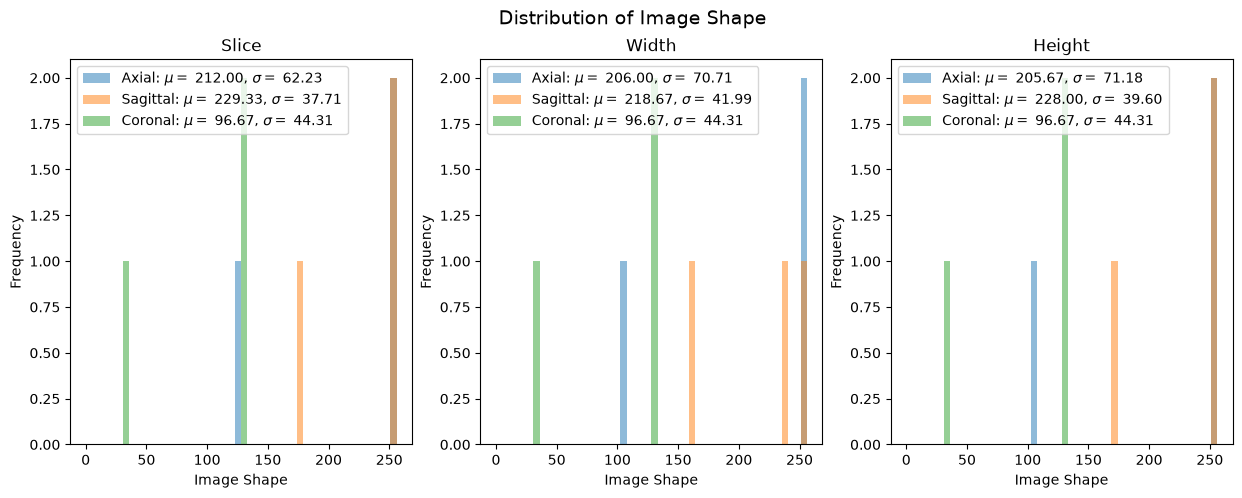

In [37]:
fig, ax = plt.subplots(1,3, figsize=(15,5))

fig.suptitle("Distribution of Image Shape", fontsize=14)

for i, dim in enumerate(["slice", "width", "height"]):
    ax[i].hist(ax_img_shape[i], bins=50, range=(0, 256), alpha=0.5, label="Axial: $\\mu=$ {:.2f}, $\\sigma=$ {:.2f}".format(
        np.mean(ax_img_shape[i]), np.std(ax_img_shape[i])))
    ax[i].hist(sag_img_shape[i], bins=50, range=(0, 256), alpha=0.5, label="Sagittal: $\\mu=$ {:.2f}, $\\sigma=$ {:.2f}".format(
        np.mean(sag_img_shape[i]), np.std(sag_img_shape[i])))
    ax[i].hist(cor_img_shape[i], bins=50, range=(0, 256), alpha=0.5, label="Coronal: $\\mu=$ {:.2f}, $\\sigma=$ {:.2f}".format(
        np.mean(cor_img_shape[i]), np.std(cor_img_shape[i])))
    ax[i].set_xlabel("Image Shape")
    ax[i].set_ylabel("Frequency")
    ax[i].set_title(dim.capitalize())
    ax[i].legend()
plt.show()